# Recommandation vidéo : prototype évalué sur KuaiRec
## Projet de stage S7 • Notebook pédagogique et reproductible

**Périmètre validé :** analyse du fichier `small_matrix.csv`, baselines, filtrage collaboratif et hybride collaboratif + popularité, évaluation hors ligne, fonction de recommandation et API de démonstration.

Ce notebook remplace la succession d'essais par une expérience structurée. Il conserve l'idée du seuil `watch_ratio ≥ 0,8` mais le traite comme une **hypothèse**, pas comme un « j'aime » explicite. Aucun modèle basé contenu n'est annoncé : les métadonnées vidéo ne sont pas fournies.

**Mode d'emploi :** placer le notebook et le CSV dans un même dossier, installer les dépendances indiquées ci-dessous, puis exécuter toutes les cellules dans l'ordre. Le CSV n'est ni modifié ni inclus dans le livrable. Les résultats enregistrés proviennent de l'exécution du fichier fourni, et non de valeurs simulées. Les fonctions et l'API sont des prototypes à auditer avant production.

**Parcours de lecture :** 1. Données → 2. Protocole → 3. Baselines → 4. Collaboratif et hybride → 5. Test final → 6. Limites et intégration. Lire l'explication avant chaque bloc de code.


In [1]:
# Configuration unique : ne pas disperser les paramètres dans les cellules.
import json, hashlib, platform, time
from pathlib import Path
import numpy as np
import pandas as pd
import scipy
from scipy. stats import rankdata
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.utils.extmath import randomized_svd
import matplotlib.pyplot as plt
from IPython.display import display

SEED = 42
SEUIL = 0.8
K = 10
RANGS = [16, 32, 64]
ALPHAS = [0.0, 0.25, 0.5, 0.75, 1.0]
# Recherche du CSV : variable RECO_CSV, puis dossier du notebook, puis dossier data/ du dépôt.
import os
_candidats = [os.environ.get("RECO_CSV"), "small_matrix.csv", "../data/small_matrix.csv"]
CSV_PATH = next((Path(c) for c in _candidats if c and Path(c).is_file()), Path("small_matrix.csv"))
OUT = Path('resultats_recommandation')
OUT.mkdir(exist_ok=True)
assert CSV_PATH.is_file(), f'CSV introuvable : {CSV_PATH.resolve()}'
versions = {'python': platform.python_version(), 'pandas': pd.__version__,
            'numpy': np.__version__, 'scipy': scipy.__version__, 'scikit-learn': sklearn.__version__}
print('Versions de cette exécution :', versions)
print('Données :', CSV_PATH.name, '| taille :', round(CSV_PATH.stat().st_size / 1e6, 2), 'Mo décimaux')
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})


Versions de cette exécution : {'python': '3.13.13', 'pandas': '3.0.3', 'numpy': '2.4.6', 'scipy': '1.17.1', 'scikit-learn': '1.8.0'}
Données : small_matrix.csv | taille : 406.16 Mo décimaux


## 1. Audit exhaustif du fichier

Une ligne représente une observation utilisateur-vidéo. On contrôle **tout le fichier**, pas seulement ses premières lignes. Les identifiants ne sont pas des variables quantitatives : leur moyenne n'a pas de sens métier.

Les colonnes temporelles manquantes ne seront pas inventées. Le protocole choisi est aléatoire, pas chronologique. Les ratios supérieurs à 1 sont autorisés ; leurs valeurs extrêmes ne sont ni supprimées ni plafonnées sans justification. Comme les modèles utilisent une cible binaire, un ratio de 571 ne reçoit pas plus de poids positif qu'un ratio de 1.

Politique de qualité : arrêter si une donnée essentielle est invalide ou si des couples sont dupliqués, plutôt que nettoyer silencieusement. Les valeurs temporelles absentes sont documentées et conservées.


In [2]:
# Lecture par blocs pour auditer toutes les colonnes tout en limitant la mémoire.
essentielles = ['user_id', 'video_id', 'play_duration', 'video_duration', 'watch_ratio']
blocs, manquants = [], None
n_lignes = 0
for bloc in pd.read_csv(CSV_PATH, chunksize=250_000):
    n_lignes += len(bloc)
    compte = bloc.isna().sum()
    manquants = compte if manquants is None else manquants.add(compte, fill_value=0)
    blocs.append(bloc[essentielles].copy())
df = pd.concat(blocs, ignore_index=True)
del blocs, bloc
qualite = pd.DataFrame({'manquants': manquants.astype(int),
                       'pourcentage': 100 * manquants / n_lignes})
display(qualite.round(4))
assert not df[essentielles].isna().any().any(), 'Valeur essentielle manquante : traitement à décider.'
assert np.isfinite(df[essentielles].to_numpy()).all(), 'Valeur non finie détectée.'
assert (df[['user_id', 'video_id']] % 1 == 0).all().all(), 'Identifiant non entier.'
invalides = (df.video_duration <= 0) | (df.play_duration < 0) | (df.watch_ratio < 0)
n_doublons = int(df.duplicated(['user_id', 'video_id']).sum())
print('Lignes :', n_lignes, '| Durées/ratios invalides :', int(invalides.sum()), '| Couples répétés :', n_doublons)
assert not invalides.any() and n_doublons == 0, 'Audit bloquant : examiner les lignes concernées.'
ratio_calcule = df.play_duration / df.video_duration
ecart_ratio = (df.watch_ratio - ratio_calcule).abs()
print('Écart absolu du ratio : médiane =', ecart_ratio.median(), ', maximum =', ecart_ratio.max())
print('Écarts > 0,001 :', int((ecart_ratio > 0.001).sum()))
display(df.loc[ecart_ratio > 0.001, essentielles].assign(ratio_recalcule=ratio_calcule[ecart_ratio > 0.001], ecart_absolu=ecart_ratio[ecart_ratio > 0.001]))
print('Étiquettes différentes source/recalcul au seuil 0,8 :', int(((df.watch_ratio >= SEUIL) != (ratio_calcule >= SEUIL)).sum()))
# Le ratio source est conservé ; les écarts sont exposés au lieu d'être masqués.
empreinte = hashlib.sha256()
with CSV_PATH.open('rb') as f:
    for b in iter(lambda: f.read(8 * 1024 * 1024), b''):
        empreinte.update(b)
sha256 = empreinte.hexdigest()
qualite.to_csv(OUT / 'qualite.csv', index_label='colonne')
print('SHA-256 du CSV :', sha256)


,manquants,pourcentage
user_id,0,0.0000
video_id,0,0.0000
play_duration,0,0.0000
video_duration,0,0.0000
time,181992,3.8916
date,181992,3.8916
timestamp,181992,3.8916
watch_ratio,0,0.0000


Lignes : 4676570 | Durées/ratios invalides : 0 | Couples répétés : 0
Écart absolu du ratio : médiane = 0.0 , maximum = 0.002921739089867259
Écarts > 0,001 : 6


,user_id,video_id,play_duration,video_duration,watch_ratio,ratio_recalcule,ecart_absolu
2064878,3239,9568,42143,5009,8.412040,8.413456,0.001416
2457853,3885,7358,183003,6610,27.682857,27.685779,0.002922
2601493,4116,9178,22760,3108,7.320817,7.323037,0.002220
3045511,4772,6315,68456,5471,12.511315,12.512521,0.001205
3656310,5606,9722,425217,8995,47.270741,47.272596,0.001855
4399127,6694,4040,28344,3091,9.167845,9.169848,0.002003


Étiquettes différentes source/recalcul au seuil 0,8 : 0
SHA-256 du CSV : 6b601cd38b2600d8734b4aede309ad73d1e201fdc4bd76d4bc7d2534793d7d15


1411 utilisateurs, 3327 vidéos, densité observée : 99.6202%


,interactions_utilisateur,interactions_video
count,1411.000000,3327.000000
mean,3314.365698,1405.641719
std,6.984852,15.739335
min,3295.000000,1315.000000
25%,3309.000000,1410.000000
50%,3315.000000,1411.000000
75%,3320.000000,1411.000000
max,3327.000000,1411.000000


,play_duration,video_duration,watch_ratio
count,4.676570e+06,4.676570e+06,4.676570e+06
mean,8.612637e+03,1.448645e+04,9.071000e-01
std,1.223661e+04,2.046711e+04,1.362300e+00
min,0.000000e+00,3.067000e+03,0.000000e+00
1%,5.430000e+02,4.885000e+03,2.230000e-02
50%,7.549000e+03,9.600000e+03,7.692000e-01
95%,1.576100e+04,4.513400e+04,1.954000e+00
99%,3.149931e+04,1.398770e+05,3.585100e+00
max,7.988155e+06,3.150720e+05,5.715214e+02


,user_id,video_id,play_duration,video_duration,watch_ratio
476794,839,10399,7988155,13977,571.521428
133274,234,5365,1502262,4500,333.836000
379777,659,7559,900756,5039,178.756896
1021416,1662,9815,656302,3834,171.179447
3175664,4950,7046,860474,5184,165.986497


,seuil,proportion_pertinente
0,0.5,0.727344
1,0.7,0.559980
2,0.8,0.474434
3,0.9,0.395984
4,1.0,0.323966
5,2.0,0.046450


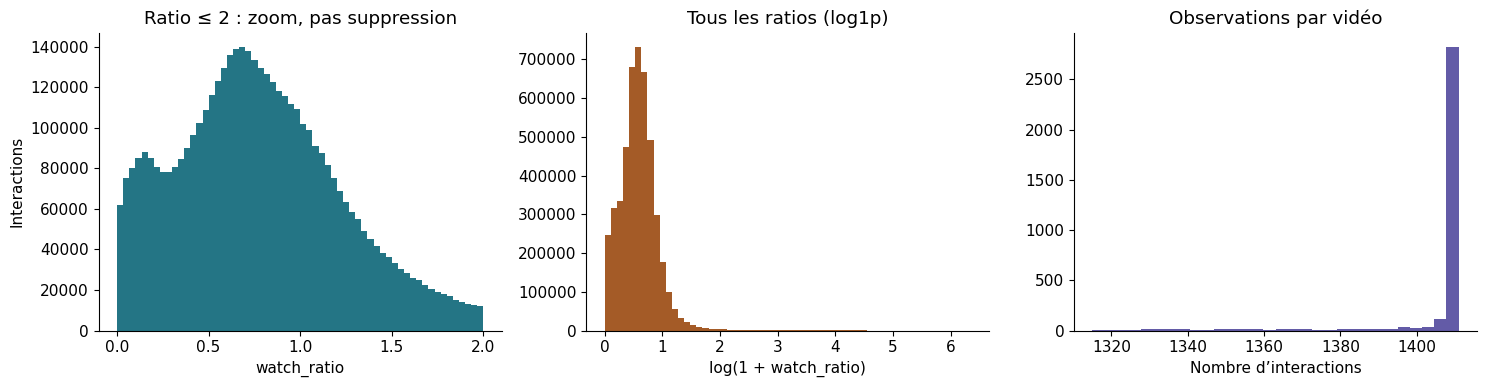

Analyse : la densité de 99.62% rend le nombre brut d’interactions peu discriminant.
Le seuil 0,8 mesure une durée cumulée relative, pas une satisfaction explicite.
Le tirage de KuaiRec et les durées des vidéos peuvent influencer les résultats ; pas de garantie de représentativité pour l’entreprise.


In [3]:
# Diagnostic des distributions et de la densité d'observation.
users = np.sort(df.user_id.unique()).astype('int64')
items = np.sort(df.video_id.unique()).astype('int64')
U, I = len(users), len(items)
densite = len(df) / (U * I)
interactions_user = df.groupby('user_id').size()
interactions_video = df.groupby('video_id').size()
print(f'{U} utilisateurs, {I} vidéos, densité observée : {densite:.4%}')
display(pd.DataFrame({'interactions_utilisateur': interactions_user.describe(),
                      'interactions_video': interactions_video.describe()}))
display(df[['play_duration', 'video_duration', 'watch_ratio']].describe(percentiles=[.01,.5,.95,.99]).round(4))
display(df.nlargest(5, 'watch_ratio')[essentielles])
seuils_explores = [0.5, 0.7, 0.8, 0.9, 1.0, 2.0]
proportions = pd.DataFrame({'seuil': seuils_explores,
    'proportion_pertinente': [(df.watch_ratio >= s).mean() for s in seuils_explores]})
display(proportions)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].hist(df.loc[df.watch_ratio <= 2, 'watch_ratio'], bins=60, color='#247585')
axes[0].set(title='Ratio ≤ 2 : zoom, pas suppression', xlabel='watch_ratio', ylabel='Interactions')
axes[1].hist(np.log1p(df.watch_ratio), bins=60, color='#a45b27')
axes[1].set(title='Tous les ratios (log1p)', xlabel='log(1 + watch_ratio)')
axes[2].hist(interactions_video, bins=30, color='#635ba7')
axes[2].set(title='Observations par vidéo', xlabel='Nombre d’interactions')
plt.tight_layout(); plt.show()
print(f'Analyse : la densité de {densite:.2%} rend le nombre brut d’interactions peu discriminant.')
print('Le seuil 0,8 mesure une durée cumulée relative, pas une satisfaction explicite.')
print('Le tirage de KuaiRec et les durées des vidéos peuvent influencer les résultats ; pas de garantie de représentativité pour l’entreprise.')


## 2. Contrat d'évaluation : fixé avant le choix du modèle

- **Population :** tous les utilisateurs du CSV valides après audit, pas seulement 100.
- **Découpage :** 20 % de test par utilisateur comme dans le notebook initial ; parmi les 80 % restants, 25 % servent à la validation. On obtient environ **60 % entraînement / 20 % validation / 20 % test**.
- **Pertinence :** ratio ≥ 0,8, hypothèse conservée. Une analyse de sensibilité sera descriptive, pas un moyen de choisir le meilleur score sur le test.
- **Candidats :** uniquement les vidéos observées dans la partition évaluée de l'utilisateur. On ne consulte pas leur pertinence pour construire cette liste. Ce protocole évalue un **classement de candidats observés**, pas la récupération dans tout le catalogue. Une observation manquante n'est donc pas inventée comme négative.
- **Sélection :** choix du rang, du poids hybride et du modèle final par NDCG@10 de validation. Puis gel des choix et un seul bilan de test.
- **Pas de réentraînement avant ce test :** tous les scores restent appris sur les mêmes 60 % pour faciliter une comparaison contrôlée. Le futur réentraînement sur davantage de données nécessitera un nouveau cycle documenté.
- **Portée :** utilisateurs et vidéos déjà connus, découpage non temporel. Cela ne mesure ni une performance future en production ni le cold start.

La validation utilise les étiquettes pour mesurer la performance, jamais pour entraîner les candidats. Le test reste hors de la sélection. Les statistiques exploratoires globales déjà examinées rendent cette étude exploratoire ; une validation externe restera nécessaire.


In [4]:
# Encodage des identifiants en indices compacts ; conservation des IDs métier.
u_idx = np.searchsorted(users, df.user_id.to_numpy())
i_idx = np.searchsorted(items, df.video_id.to_numpy())
# Conserver les ratios en float64 évite de déplacer artificiellement les seuils.
ratio = np.full((U, I), np.nan, dtype=np.float64)
ratio[u_idx, i_idx] = df.watch_ratio.to_numpy(np.float64)
train_mask = np.zeros((U, I), dtype=bool)
val_mask = np.zeros_like(train_mask)
test_mask = np.zeros_like(train_mask)
# Des graines distinctes par utilisateur évitent des partitions identiques
# lorsque plusieurs utilisateurs ont exactement les mêmes vidéos observées.
rng_split = np.random.default_rng(SEED)
for u in range(U):
    observes = np.flatnonzero(np.isfinite(ratio[u]))
    dev, test = train_test_split(observes, test_size=0.2, random_state=int(rng_split.integers(0, 2**31-1)))
    train, val = train_test_split(dev, test_size=0.25, random_state=int(rng_split.integers(0, 2**31-1)))
    train_mask[u, train] = True
    val_mask[u, val] = True
    test_mask[u, test] = True
assert not (train_mask & val_mask).any()
assert not (train_mask & test_mask).any()
assert not (val_mask & test_mask).any()
assert np.array_equal(train_mask | val_mask | test_mask, np.isfinite(ratio))
assert (val_mask.sum(axis=1) >= K).all() and (test_mask.sum(axis=1) >= K).all()
assert (train_mask.sum(axis=0) > 0).all(), 'Vidéo inconnue dans le protocole warm-start.'
assert (train_mask.sum(axis=1) > 0).all()
print('Minimum observations entraînement par vidéo :', int(train_mask.sum(axis=0).min()))
labels = (ratio >= SEUIL).astype(np.float32)
display(pd.DataFrame({'partition': ['entraînement','validation','test'],
    'interactions': [int(m.sum()) for m in [train_mask,val_mask,test_mask]],
    'utilisateurs': [int((m.sum(axis=1)>0).sum()) for m in [train_mask,val_mask,test_mask]]}))
# Sauvegarde des partitions exactes pour refaire les mêmes expériences.
np.savez_compressed(OUT / 'partitions.npz', users=users, items=items,
                    train=train_mask, validation=val_mask, test=test_mask)


Minimum observations entraînement par vidéo : 753


,partition,interactions,utilisateurs
0,entraînement,2805059,1411
1,validation,935611,1411
2,test,935900,1411


### Métriques et contrôles communs

**Precision@10** : positifs dans le top 10 / 10. **Recall@10** : positifs retrouvés / positifs dans les candidats observés. **NDCG@10** : récompense les positifs placés en haut, normalisée par le meilleur ordre possible pour ces candidats. Les moyennes sont calculées par utilisateur (macro-moyennes).

Si un utilisateur n'a aucun positif parmi ses candidats, précision = 0 ; rappel et NDCG sont laissés indéfinis et exclus de leur moyenne, avec un compteur explicite. Les ex æquo sont départagés par identifiant vidéo croissant. La couverture mesure la fraction de vidéos du catalogue recommandées au moins une fois ; ce n'est pas une mesure de qualité à elle seule.


In [5]:
def evaluer(scores, masque, seuil=SEUIL, utilisateurs=None):
    """Évaluer un score global ou personnalisé sur des candidats observés identiques."""
    ids = np.arange(U) if utilisateurs is None else np.asarray(utilisateurs)
    lignes, tops = [], []
    for u in ids:
        candidats = np.flatnonzero(masque[u])
        assert len(candidats) >= K
        s = scores[candidats] if scores.ndim == 1 else scores[u, candidats]
        assert np.isfinite(s).all()
        ordre = np.lexsort((items[candidats], -s))
        top = candidats[ordre[:K]]
        assert len(np.unique(top)) == K and not train_mask[u, top].any()
        rel = (ratio[u, top] >= seuil).astype(float)
        n_positifs = int((ratio[u, candidats] >= seuil).sum())
        discounts = 1 / np.log2(np.arange(2, K + 2))
        ideal = discounts[:min(K, n_positifs)].sum()
        lignes.append({'user_id': int(users[u]), 'precision': rel.sum()/K,
            'recall': rel.sum()/n_positifs if n_positifs else np.nan,
            'ndcg': float(rel @ discounts / ideal) if ideal else np.nan,
            'positifs_candidats': n_positifs, 'nombre_candidats': len(candidats)})
        tops.append(top)
    return pd.DataFrame(lignes), np.asarray(tops)

def resumer(nom, per_user, tops):
    return {'modele': nom, 'Precision@10': per_user.precision.mean(),
            'Recall@10': per_user.recall.mean(), 'NDCG@10': per_user.ndcg.mean(),
            'couverture_catalogue': len(np.unique(tops))/I,
            'utilisateurs': len(per_user),
            'sans_positif': int((per_user.positifs_candidats == 0).sum())}


## 3. Baselines : ne pas comparer le collaboratif à une seule référence faible

1. **Aléatoire** : scores uniformes figés par graine (un tirage, pas une moyenne sur de nombreuses graines).
2. **Nombre d'interactions** : la baseline d'origine, fondée sur l'exposition.
3. **Nombre d'interactions pertinentes** : compte les réponses positives.
4. **Taux pertinent lissé** : proportion positive, régularisée avec 20 pseudo-observations au taux global d'entraînement. Ce lissage est fixé a priori, pas optimisé sur le test.

Le filtrage des vidéos connues ne suffit pas à rendre un classement personnalisé : ces baselines partagent un score vidéo global.


In [6]:
expositions = train_mask.sum(axis=0).astype(np.float32)
positifs = (labels * train_mask).sum(axis=0)
taux_global = float(positifs.sum() / expositions.sum())
LISSAGE = 20.0
taux_lisse = (positifs + LISSAGE * taux_global) / (expositions + LISSAGE)
rng = np.random.default_rng(SEED)
scores_modeles = {
    'Aleatoire': rng.random((U,I), dtype=np.float32),
    'Nb_interactions': expositions,
    'Nb_pertinentes': positifs,
    'Taux_lisse': taux_lisse,
}
validation = []
for nom, scores in scores_modeles.items():
    mesures, tops = evaluer(scores, val_mask)
    validation.append(resumer(nom, mesures, tops))
display(pd.DataFrame(validation).round(5))
print('Taux positif global d’entraînement :', taux_global)


,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
0,Aleatoire,0.47945,0.01524,0.47944,0.98798,1411,0
1,Nb_interactions,0.45386,0.01426,0.43389,0.03427,1411,0
2,Nb_pertinentes,0.89440,0.02951,0.90237,0.03006,1411,0
3,Taux_lisse,0.89957,0.02971,0.90616,0.03066,1411,0


Taux positif global d’entraînement : 0.47441035509109497


## 4. Filtrage collaboratif : factorisation de préférences résiduelles

On exploite ici les réponses **observées positives et négatives** (selon le seuil), plutôt que transformer toute interaction en « like ». Pour chaque utilisateur, on calcule son taux positif sur l'entraînement. On centre les observations autour de cette moyenne, et on remplit les cases non disponibles avec un résidu neutre nul.

Une SVD tronquée approxime cette matrice par des facteurs utilisateur et vidéo. Les goûts similaires correspondent à des directions latentes proches. Le score reconstruit est un **score de classement, pas une probabilité**.

**Limite importante :** ce choix est une SVD pédagogique avec imputation neutre, pas un ALS pondéré ni une optimisation masquée parfaite. Les absences sont distinguées par les masques, mais leur résidu neutre influence l'approximation. Comparer les résultats est indispensable : la sophistication ne garantit aucun gain.


In [7]:
moyenne_user = (labels * train_mask).sum(axis=1) / train_mask.sum(axis=1)
residus = np.where(train_mask, labels - moyenne_user[:,None], 0).astype(np.float32)
facteurs = {}
for rang in RANGS:
    debut = time.perf_counter()
    gauche, valeurs, droite = randomized_svd(residus, n_components=rang,
        n_iter=5, random_state=SEED)
    facteurs_user = (gauche * valeurs).astype(np.float32)
    facteurs_video = droite.astype(np.float32)
    scores = moyenne_user[:,None] + facteurs_user @ facteurs_video
    nom = f'SVD_{rang}'
    scores_modeles[nom] = scores.astype(np.float32)
    facteurs[nom] = (facteurs_user, facteurs_video)
    mesures, tops = evaluer(scores_modeles[nom], val_mask)
    validation.append(resumer(nom, mesures, tops))
    print(nom, 'durée entraînement (s) :', round(time.perf_counter()-debut,2))
val_df = pd.DataFrame(validation)
meilleur_cf = val_df[val_df.modele.str.startswith('SVD_')].sort_values('NDCG@10', ascending=False).iloc[0].modele
print('Collaboratif retenu sur validation :', meilleur_cf)
display(val_df.round(5))


SVD_16 durée entraînement (s) : 0.27
SVD_32 durée entraînement (s) : 0.27
SVD_64 durée entraînement (s) : 0.3
Collaboratif retenu sur validation : SVD_16


,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
0,Aleatoire,0.47945,0.01524,0.47944,0.98798,1411,0
1,Nb_interactions,0.45386,0.01426,0.43389,0.03427,1411,0
2,Nb_pertinentes,0.89440,0.02951,0.90237,0.03006,1411,0
3,Taux_lisse,0.89957,0.02971,0.90616,0.03066,1411,0
4,SVD_16,0.87144,0.02871,0.87430,0.49143,1411,0
5,SVD_32,0.84132,0.02765,0.84211,0.56658,1411,0
6,SVD_64,0.81991,0.02687,0.82074,0.62970,1411,0


## 5. Hybride collaboratif + popularité

On combine le collaboratif sélectionné et le taux pertinent lissé. Pour éviter de mélanger des échelles différentes, on convertit leurs scores en rangs percentiles sur le catalogue. Le poids α est choisi uniquement sur la validation.

Score hybride = α × rang collaboratif + (1 − α) × rang de popularité. α = 0 ou 1 peut gagner : dans ce cas, la validation ne soutient pas une combinaison intermédiaire. Cet hybride **n'utilise pas de contenu vidéo** et ne résout pas le démarrage d'une vidéo inconnue.


In [8]:
rang_cf = (rankdata(scores_modeles[meilleur_cf], axis=1, method='average') / I).astype(np.float32)
rang_pop = (rankdata(taux_lisse, method='average') / I).astype(np.float32)
for alpha in ALPHAS:
    nom = f'Hybride_{alpha:.2f}'
    scores_modeles[nom] = alpha * rang_cf + (1-alpha) * rang_pop[None,:]
    mesures, tops = evaluer(scores_modeles[nom], val_mask)
    validation.append(resumer(nom, mesures, tops))
val_df = pd.DataFrame(validation)
# Exclure l'aléatoire comme candidat de livraison, mais le conserver dans l'évaluation.
selection = val_df[val_df.modele != 'Aleatoire'].sort_values('NDCG@10', ascending=False, kind='stable')
modele_retenu = str(selection.iloc[0].modele)
meilleure_baseline = str(val_df[val_df.modele.isin(['Nb_interactions','Nb_pertinentes','Taux_lisse'])]
    .sort_values('NDCG@10', ascending=False, kind='stable').iloc[0].modele)
meilleur_hybride = str(val_df[val_df.modele.str.startswith('Hybride_')]
    .sort_values('NDCG@10', ascending=False, kind='stable').iloc[0].modele)
print('Choix gelé AVANT test :', modele_retenu)
print('Baseline de comparaison choisie sur validation :', meilleure_baseline)
display(selection.round(5))
val_df.to_csv(OUT/'validation.csv', index=False)


Choix gelé AVANT test : Hybride_0.25
Baseline de comparaison choisie sur validation : Taux_lisse


,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
8,Hybride_0.25,0.90425,0.02990,0.90913,0.07454,1411,0
3,Taux_lisse,0.89957,0.02971,0.90616,0.03066,1411,0
7,Hybride_0.00,0.89957,0.02971,0.90616,0.03066,1411,0
9,Hybride_0.50,0.90071,0.02977,0.90563,0.13225,1411,0
2,Nb_pertinentes,0.89440,0.02951,0.90237,0.03006,1411,0
10,Hybride_0.75,0.89320,0.02949,0.89799,0.22453,1411,0
4,SVD_16,0.87144,0.02871,0.87430,0.49143,1411,0
11,Hybride_1.00,0.87144,0.02871,0.87430,0.49143,1411,0
5,SVD_32,0.84132,0.02765,0.84211,0.56658,1411,0
6,SVD_64,0.81991,0.02687,0.82074,0.62970,1411,0


## 6. Bilan final sur le test réservé

On évalue les baselines et les candidats déjà sélectionnés, sans changer le rang ni le poids en fonction du test. Aucun score n'est comparable directement à l'ancien 0,417 : population, partition d'entraînement et définition des candidats ont changé.

Un résultat élevé doit être rapproché du taux de pertinence et de la performance aléatoire. Une hausse de Precision@10 ne prouve ni une personnalisation utile pour chacun, ni un bénéfice produit en production.


,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
0,Aleatoire,0.47512,0.01504,0.46982,0.98377,1411,0
1,Nb_interactions,0.45507,0.01437,0.43467,0.03276,1411,0
2,Nb_pertinentes,0.89724,0.02967,0.90284,0.03126,1411,0
3,Taux_lisse,0.90269,0.02985,0.90968,0.02976,1411,0
4,SVD_16,0.87123,0.02862,0.87538,0.49173,1411,0
5,Hybride_0.25,0.90220,0.02980,0.90805,0.07665,1411,0


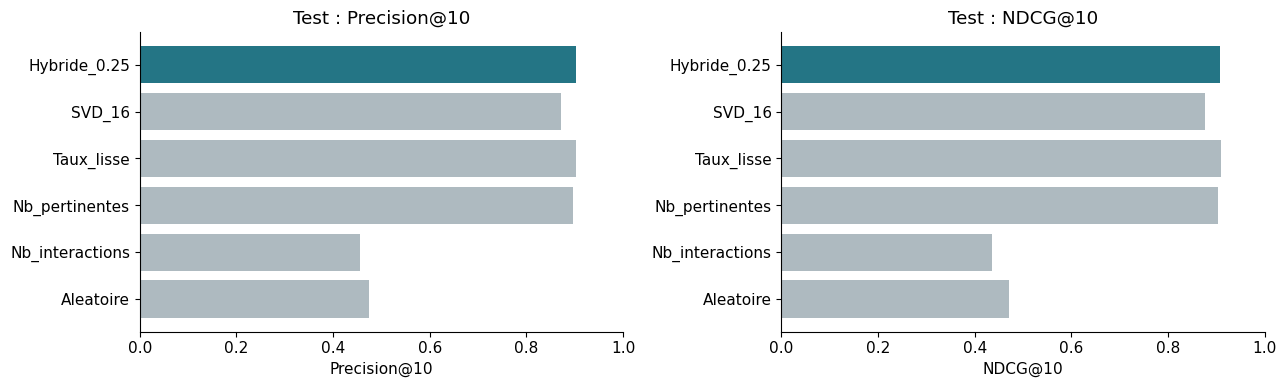

,modele,reference,difference_NDCG,IC95_bas,IC95_haut
0,SVD_16,Taux_lisse,-0.03430,-0.04164,-0.02724
1,Hybride_0.25,Taux_lisse,-0.00163,-0.00559,0.00215


IC conditionnels à ce découpage : ils ne couvrent pas la variabilité entre jeux de données ni tous les biais de sélection.


In [9]:
noms_test = list(dict.fromkeys(['Aleatoire','Nb_interactions','Nb_pertinentes','Taux_lisse',
                              meilleur_cf, meilleur_hybride, modele_retenu]))
test_detail, test_tops, lignes_test = {}, {}, []
for nom in noms_test:
    per_user, tops = evaluer(scores_modeles[nom], test_mask)
    test_detail[nom], test_tops[nom] = per_user, tops
    lignes_test.append(resumer(nom, per_user, tops))
test_df = pd.DataFrame(lignes_test)
assert test_df[['Precision@10','Recall@10','NDCG@10','couverture_catalogue']].ge(0).all().all()
assert test_df[['Precision@10','Recall@10','NDCG@10','couverture_catalogue']].le(1).all().all()
assert (test_df.utilisateurs == U).all()
display(test_df.round(5))
test_df.to_csv(OUT/'test_comparaison.csv', index=False)
pd.concat([d.assign(modele=n) for n,d in test_detail.items()]).to_csv(OUT/'test_par_utilisateur.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=(13,4))
for ax, metrique in zip(axes, ['Precision@10','NDCG@10']):
    ax.barh(test_df.modele, test_df[metrique], color=['#247585' if n==modele_retenu else '#aebac0' for n in test_df.modele])
    ax.set(xlabel=metrique, title='Test : '+metrique, xlim=(0,1))
plt.tight_layout(); plt.show()
# Intervalle bootstrap apparié : mêmes utilisateurs, comparaisons utilisateur par utilisateur.
def bootstrap_difference(a, b, repetitions=2000):
    differences = np.asarray(a-b, dtype=float)
    differences = differences[np.isfinite(differences)]
    rng = np.random.default_rng(SEED)
    tirages = rng.choice(differences, size=(repetitions,len(differences)), replace=True).mean(axis=1)
    return float(differences.mean()), np.quantile(tirages,[.025,.975])
comparaisons = []
for nom in list(dict.fromkeys([meilleur_cf, meilleur_hybride, modele_retenu])):
    difference, bornes = bootstrap_difference(test_detail[nom].ndcg, test_detail[meilleure_baseline].ndcg)
    comparaisons.append({'modele': nom, 'reference': meilleure_baseline,
       'difference_NDCG': difference, 'IC95_bas': bornes[0], 'IC95_haut': bornes[1]})
incertitude = pd.DataFrame(comparaisons)
display(incertitude.round(5))
incertitude.to_csv(OUT/'incertitude.csv',index=False)
print('IC conditionnels à ce découpage : ils ne couvrent pas la variabilité entre jeux de données ni tous les biais de sélection.')


In [10]:
# Sensibilité descriptive : classements gelés, aucune nouvelle sélection sur le test.
sensibilite = []
for seuil in [0.5, 0.8, 1.0]:
    for nom in list(dict.fromkeys(['Aleatoire', meilleure_baseline, modele_retenu])):
        p, t = evaluer(scores_modeles[nom], test_mask, seuil=seuil)
        sensibilite.append(dict(resumer(nom,p,t), seuil=seuil))
sensibilite_df = pd.DataFrame(sensibilite)
display(sensibilite_df[['seuil','modele','Precision@10','Recall@10','NDCG@10']].round(5))
sensibilite_df.to_csv(OUT/'sensibilite.csv',index=False)
print('Changer le seuil change la définition de la cible. Les scores entre seuils ne mesurent pas le même problème.')


,seuil,modele,Precision@10,Recall@10,NDCG@10
0,0.5,Aleatoire,0.73125,0.01516,0.72929
1,0.5,Taux_lisse,0.94833,0.01994,0.95191
2,0.5,Hybride_0.25,0.94685,0.01989,0.94951
3,0.8,Aleatoire,0.47512,0.01504,0.46982
4,0.8,Taux_lisse,0.90269,0.02985,0.90968
5,0.8,Hybride_0.25,0.90220,0.02980,0.90805
6,1.0,Aleatoire,0.32821,0.01513,0.32455
7,1.0,Taux_lisse,0.85684,0.04434,0.86965
8,1.0,Hybride_0.25,0.85344,0.04409,0.86482


Changer le seuil change la définition de la cible. Les scores entre seuils ne mesurent pas le même problème.


## 7. Cold start utilisateur : expérience séparée de la personnalisation

Le test principal ne porte pas sur de nouveaux utilisateurs. Pour un diagnostic distinct, on retire tous les exemples d'entraînement d'un groupe aléatoire de 10 % d'utilisateurs et on calcule une popularité lissée uniquement à partir des autres utilisateurs. On évalue cette solution de repli sur les vidéos de test observées des utilisateurs retirés.

Ce test mesure une solution **non personnalisée sans historique**, avec un lissage déjà fixé. Il ne valide pas une généralisation commerciale. Aucune donnée de contenu n'est disponible pour tester correctement de nouvelles vidéos : cet axe reste hors périmètre expérimental.


In [11]:
rng_cold = np.random.default_rng(SEED+100)
cold_users = np.sort(rng_cold.choice(U, size=max(1, int(np.ceil(.1*U))), replace=False))
train_cold = train_mask.copy()
train_cold[cold_users] = False
assert not train_cold[cold_users].any()
cold_n = train_cold.sum(axis=0)
cold_p = (labels * train_cold).sum(axis=0)
cold_global = cold_p.sum()/cold_n.sum()
cold_scores = (cold_p + LISSAGE*cold_global)/(cold_n+LISSAGE)
cold_detail, cold_tops = evaluer(cold_scores, test_mask, utilisateurs=cold_users)
cold_random, cold_random_tops = evaluer(scores_modeles['Aleatoire'], test_mask, utilisateurs=cold_users)
cold_df = pd.DataFrame([resumer('Repli_popularite_sans_historique',cold_detail,cold_tops),
                        resumer('Aleatoire_meme_groupe',cold_random,cold_random_tops)])
display(cold_df.round(5))
cold_df.to_csv(OUT/'cold_start_utilisateur.csv',index=False)


,modele,Precision@10,Recall@10,NDCG@10,couverture_catalogue,utilisateurs,sans_positif
0,Repli_popularite_sans_historique,0.91127,0.02998,0.91989,0.02435,142,0
1,Aleatoire_meme_groupe,0.48662,0.01527,0.47910,0.33844,142,0


## 8. Conclusions calculées, pas promesses de performance

La synthèse ci-dessous est produite à partir des tableaux exécutés. Elle conserve le modèle choisi en validation, même si un autre obtient un meilleur score sur ce test. Pour interpréter un gain, regarder simultanément sa taille, l'incertitude, la couverture et les limites du protocole.


In [12]:
resultats = test_df.set_index('modele')
selection_test = resultats.loc[modele_retenu]
base_test = resultats.loc[meilleure_baseline]
delta = float(selection_test['NDCG@10'] - base_test['NDCG@10'])
print(f"Modèle retenu par validation : {modele_retenu}.")
print(f"Test sur {U} utilisateurs : Precision@10={selection_test['Precision@10']:.4f}, "
      f"NDCG@10={selection_test['NDCG@10']:.4f}, couverture={selection_test['couverture_catalogue']:.2%}.")
print(f"Référence {meilleure_baseline} : différence NDCG absolue={delta:+.4f}.")
if modele_retenu == meilleure_baseline:
    print('La validation ne justifie pas de livrer un modèle plus complexe que cette baseline.')
else:
    d,ci = bootstrap_difference(test_detail[modele_retenu].ndcg,test_detail[meilleure_baseline].ndcg)
    if ci[0] > 0:
        print('Gain positif sur ce test avec IC bootstrap apparié au-dessus de zéro ; confirmation externe nécessaire.')
    elif ci[1] < 0:
        print('Le candidat sélectionné est moins bon que la référence sur ce test : ne pas cacher ce résultat.')
    else:
        print('IC du gain recouvrant zéro : avantage non établi par cette expérience.')
print('Ce travail ne démontre pas une hausse du temps de visionnage, du taux de clic ou de la rétention.')
print('Les tests de production, les métadonnées vidéo, la protection des données et le dimensionnement restent à traiter avec l’entreprise.')
print('Aucune conclusion causale sur les préférences : le watch_ratio reste un signal indirect.')


Modèle retenu par validation : Hybride_0.25.
Test sur 1411 utilisateurs : Precision@10=0.9022, NDCG@10=0.9081, couverture=7.66%.
Référence Taux_lisse : différence NDCG absolue=-0.0016.
IC du gain recouvrant zéro : avantage non établi par cette expérience.
Ce travail ne démontre pas une hausse du temps de visionnage, du taux de clic ou de la rétention.
Les tests de production, les métadonnées vidéo, la protection des données et le dimensionnement restent à traiter avec l’entreprise.
Aucune conclusion causale sur les préférences : le watch_ratio reste un signal indirect.


## Lecture critique des résultats de cette exécution

### Données : ce qui est établi
- Les **4 676 570 lignes** ont été contrôlées ; aucun couple utilisateur-vidéo répété, aucune durée invalide et aucune valeur essentielle manquante n'ont été détectés.
- **181 992 lignes (3,89157 %) manquent dans chacune des colonnes temporelles**. Ce constat porte sur tout le fichier, pas sur l'extrait initial à 3,79 %.
- Six ratios présentent un écart absolu supérieur à 0,001 avec le calcul durée regardée / durée vidéo. Ils sont affichés dans l'audit ; le ratio source est conservé. Il faut documenter cette différence, pas affirmer que toutes les valeurs sont exactement identiques.
- La matrice observée est dense à **99,6202 %**. Cette propriété facilite les évaluations sur réponses connues, mais ne supprime pas les biais du jeu de données.

### Modèles : le résultat important n'est pas seulement le score le plus élevé
Le meilleur rang collaboratif sur validation est **16**. Le poids hybride retenu est **25 % de rang collaboratif et 75 % de rang de popularité**. Ce poids porte sur les rangs percentiles, pas directement sur des probabilités.

Le candidat retenu sur validation, **Hybride_0.25**, obtient sur le test :
- Precision@10 : **0.9022** ;
- NDCG@10 : **0.9081** ;
- couverture du catalogue : **7.66%**.

La baseline **Taux_lisse** atteint une Precision@10 de **0.9027**, une NDCG@10 de **0.9097** et une couverture de **2.98%**. L'hybride ne démontre donc **pas un gain de précision ou de NDCG** face à cette référence. Sa différence NDCG vaut -0.0016, avec IC bootstrap 95 % [-0.0056 ; +0.0022], qui recouvre zéro. Cela n'établit pas non plus une équivalence statistique.

En revanche, sa couverture est plus élevée dans cette expérience. C'est un compromis à discuter avec l'entreprise, **pas une mesure de diversité sémantique**. Le collaboratif seul couvre encore davantage de vidéos, mais perd en pertinence moyenne dans ce protocole. Il serait incorrect d'en conclure que tout filtrage collaboratif est inférieur : un seul modèle pédagogique et une grille limitée ont été testés.

### Pourquoi les scores semblent élevés
La pertinence est définie par un signal indirect relativement fréquent. Parmi plusieurs centaines de candidats observés, une méthode peut choisir dix vidéos généralement bien regardées. Un score d'environ 0,90 ne signifie donc ni 90 % de satisfaction réelle, ni 90 % de réussite sur tous les utilisateurs futurs.

L'ancien **0,417 n'est pas une référence directement comparable** : il concernait 100 utilisateurs, un entraînement sur 80 % et des candidats différents. Ici, les 1 411 utilisateurs sont évalués avec des partitions 60/20/20 et des candidats observés. Ce notebook ne revendique pas un passage de 41,7 % à 90 % à protocole constant.

Le rappel est faible malgré une précision élevée : les utilisateurs ont beaucoup plus de dix positifs dans leurs candidats. Retrouver dix éléments ne couvre qu'une petite partie de ces positifs. Ce n'est pas une contradiction ; précision et rappel répondent à des questions différentes.

### Décision et prochaine étape scientifique
Conserver le candidat choisi sur validation comme démonstrateur, et la popularité lissée comme référence forte. Ne pas changer de gagnant après consultation du test. Avant toute revendication produit, tester d'autres découpages, une validation temporelle adaptée aux dates manquantes, puis les données de l'entreprise. La stratégie de cold start utilisateur est un repli non personnalisé ; le cold start vidéo reste non évalué faute de métadonnées.


## 9. Prototype de recommandation et export

Le prototype utilise les scores gelés de l'expérience. Pour un utilisateur connu, il exclut ses vidéos d'entraînement. Pour un utilisateur inconnu, il renvoie une popularité lissée non personnalisée. Une liste de vidéos déjà vues peut être transmise par l'application ; elle est filtrée en plus.

**Différence avec le test :** en service, on classe le catalogue connu admissible, pas seulement des candidats observés du test. Les métriques hors ligne ne sont donc pas une mesure directe de ce service. Les observations de validation/test ne sont pas injectées dans le modèle exporté.

Cet export est un instantané de démonstration, pas un modèle réentraîné sur tout l'historique. Il ne gère ni l'arrivée de nouveaux contenus, ni les mises à jour en temps réel. Les scores ne sont pas exposés comme probabilités.


In [13]:
scores_livres = scores_modeles[modele_retenu]
if scores_livres.ndim == 1:
    scores_livres = np.broadcast_to(scores_livres, (U,I)).copy()
user_lookup = {int(uid): pos for pos,uid in enumerate(users)}
def recommander(user_id, k=10, deja_vues=None):
    """Retourner au plus k IDs vidéo du catalogue connu, sans recommander des vues connues."""
    if not isinstance(k, int) or not 1 <= k <= 100:
        raise ValueError('k doit être un entier entre 1 et 100')
    uid = int(user_id)
    u = user_lookup.get(uid)
    scores = taux_lisse if u is None else scores_livres[u]
    disponible = np.ones(I, dtype=bool) if u is None else ~train_mask[u].copy()
    if deja_vues is not None:
        disponible &= ~np.isin(items, list(deja_vues))
    candidats = np.flatnonzero(disponible)
    ordre = np.lexsort((items[candidats], -scores[candidats]))
    choix = candidats[ordre[:k]]
    return {'user_id': uid, 'mode': 'repli_popularite' if u is None else modele_retenu,
            'video_ids': items[choix].astype(int).tolist(),
            'nombre_retourne': len(choix)}

exemple_connu = recommander(int(users[0]))
exemple_inconnu = recommander(int(users.max())+1)
print('Utilisateur connu :', exemple_connu)
print('Utilisateur inconnu :', exemple_inconnu)
assert len(exemple_connu['video_ids']) == K
assert len(set(exemple_connu['video_ids'])) == K
assert not set(exemple_connu['video_ids']) & set(items[train_mask[0]])
exclus = exemple_connu['video_ids']
assert not set(recommander(int(users[0]),deja_vues=exclus)['video_ids']) & set(exclus)
try:
    recommander(int(users[0]),0)
    raise AssertionError('Le test de validation aurait dû échouer')
except ValueError:
    pass
print('Tests de la fonction : OK (taille, unicité, exclusion, repli, paramètre invalide).')
np.savez_compressed(OUT/'modele_demo.npz', users=users,items=items,
    scores=scores_livres.astype(np.float32),seen=train_mask,popularity=taux_lisse.astype(np.float32))
manifest = {'modele':modele_retenu,'collaboratif':meilleur_cf,'hybride':meilleur_hybride,
 'baseline_reference':meilleure_baseline,'seed':SEED,'seuil':SEUIL,'k':K,
 'csv_sha256':sha256,'versions':versions,'lignes':len(df),'utilisateurs':U,'videos':I,
 'split':'60/20/20 par utilisateur (approximatif, arrondis par groupe)',
 'candidats_test':'interactions observees du test par utilisateur',
 'exemple_connu':exemple_connu,'exemple_inconnu':exemple_inconnu}
(OUT/'manifest.json').write_text(json.dumps(manifest,ensure_ascii=False,indent=2),encoding='utf-8')


Utilisateur connu : {'user_id': 14, 'mode': 'Hybride_0.25', 'video_ids': [5464, 8366, 3344, 7594, 5995, 314, 5365, 4715, 1445, 9261], 'nombre_retourne': 10}
Utilisateur inconnu : {'user_id': 7163, 'mode': 'repli_popularite', 'video_ids': [6222, 2130, 1305, 7383, 5464, 4040, 600, 9178, 8524, 8298], 'nombre_retourne': 10}
Tests de la fonction : OK (taille, unicité, exclusion, repli, paramètre invalide).


1094

## 10. API locale de démonstration

La cellule suivante crée `api_demo.py`, servi uniquement sur **127.0.0.1** par défaut. Elle n'ouvre pas un serveur qui bloquerait le notebook. Pour le lancer, dans un terminal :

```bash
python resultats_recommandation/api_demo.py
```

Exemple de requête : `http://127.0.0.1:8000/recommendations?user_id=14&k=10`

Ajouter `&seen=183,148` pour exclure des IDs connus de l'application. `GET /health` donne l'état du service. Les réponses sont au format JSON. Arrêt : Ctrl+C.

Cette API repose sur la bibliothèque standard Python et NumPy, sans framework supplémentaire. **Pas de production en l'état :** il manque authentification, contrôle d'accès aux historiques, catalogue actif/modération, HTTPS, supervision, tests de charge, mises à jour du modèle et règles de protection des données. L'absence de métadonnées interdit de scorer une vidéo réellement nouvelle.


In [14]:
api_source = r'''
"""API locale de démonstration. Ne pas exposer telle quelle sur Internet."""
import json
from pathlib import Path
from http.server import BaseHTTPRequestHandler, ThreadingHTTPServer
from urllib.parse import urlparse, parse_qs
import numpy as np
ROOT = Path(__file__).resolve().parent
class Recommender:
    def __init__(self, path=ROOT/'modele_demo.npz'):
        with np.load(path, allow_pickle=False) as data:
            self.users=data['users']; self.items=data['items']; self.scores=data['scores']
            self.seen=data['seen']; self.pop=data['popularity']
        self.lookup={int(u):i for i,u in enumerate(self.users)}
    def recommend(self, user_id, k=10, seen=()):
        if not 1 <= k <= 100: raise ValueError('k doit être entre 1 et 100')
        u=self.lookup.get(int(user_id))
        scores=self.pop if u is None else self.scores[u]
        available=np.ones(len(self.items),bool) if u is None else ~self.seen[u].copy()
        available &= ~np.isin(self.items,list(seen))
        candidates=np.flatnonzero(available)
        order=np.lexsort((self.items[candidates],-scores[candidates]))
        videos=self.items[candidates[order[:k]]].astype(int).tolist()
        return {'user_id':int(user_id),'video_ids':videos,'nombre_retourne':len(videos),
                'mode':'repli_popularite' if u is None else 'modele_selectionne'}

def traiter(path, service):
    """Route pure, testable sans connexion réseau."""
    url=urlparse(path)
    if url.path=='/health': return 200, {'status':'ok'}
    if url.path!='/recommendations': return 404, {'error':'Route inconnue'}
    try:
        q=parse_qs(url.query)
        uid=int(q['user_id'][0]); k=int(q.get('k',['10'])[0])
        seen=[int(x) for x in q.get('seen',[''])[0].split(',') if x]
        return 200, service.recommend(uid,k,seen)
    except (KeyError,ValueError,TypeError):
        return 400, {'error':'Paramètres invalides : user_id entier, k entre 1 et 100, seen IDs séparés par virgules'}

if __name__=='__main__':
    service=Recommender()
    class Handler(BaseHTTPRequestHandler):
        def do_GET(self):
            status,payload=traiter(self.path,service)
            body=json.dumps(payload,ensure_ascii=False).encode('utf-8')
            self.send_response(status)
            self.send_header('Content-Type','application/json; charset=utf-8')
            self.send_header('Content-Length',str(len(body)))
            self.end_headers(); self.wfile.write(body)
    server=ThreadingHTTPServer(('127.0.0.1',8000),Handler)
    print('API locale : http://127.0.0.1:8000 ; arrêt Ctrl+C')
    try: server.serve_forever()
    except KeyboardInterrupt: server.server_close()
'''
(OUT/'api_demo.py').write_text(api_source, encoding='utf-8')
print('API écrite dans', OUT/'api_demo.py')


API écrite dans resultats_recommandation\api_demo.py


In [15]:
# Tests de l'export et des routes. Aucun serveur ni appel réseau n'est nécessaire.
import importlib.util
spec = importlib.util.spec_from_file_location('api_demo', OUT/'api_demo.py')
api = importlib.util.module_from_spec(spec)
spec.loader.exec_module(api)
service = api.Recommender()
assert service.recommend(int(users[0]))['video_ids'] == exemple_connu['video_ids']
assert api.traiter('/health',service)[0] == 200
assert api.traiter('/inconnue',service)[0] == 404
assert api.traiter('/recommendations',service)[0] == 400
assert api.traiter('/recommendations?user_id=14&k=0',service)[0] == 400
assert api.traiter('/recommendations?user_id=abc',service)[0] == 400
assert api.traiter(f'/recommendations?user_id={int(users[0])}&k=10',service)[1]['video_ids'] == exemple_connu['video_ids']
assert service.recommend(int(users.max())+1)['mode'] == 'repli_popularite'
(OUT/'tests.json').write_text(json.dumps({'fonction_recommandation':'OK','export_rechargement':'OK',
 'routes_hors_reseau':'OK','serveur_HTTP_en_reseau':'non testé ici','production':'non validée'},indent=2),encoding='utf-8')
print('Export rechargé et routes testées : OK. Transport HTTP et charge non testés ici.')


Export rechargé et routes testées : OK. Transport HTTP et charge non testés ici.


## 11. Remise à l'entreprise et travail restant

**Livré dans cette expérience :** audit complet, notebook expliqué et exécuté, comparaison hors ligne, paramètres choisis sur validation, tableaux détaillés, modèle de démonstration, fonction de recommandation et API locale testée au niveau des routes.

**Non démontré / non livré :** plateforme vidéo complète, modèle basé contenu, cold start vidéo, gain métier causal, conformité juridique auditée, sécurité de production, disponibilité en charge et adaptation aux données de l'entreprise.

### Plan d'intégration
1. Faire valider le schéma des événements (utilisateur, vidéo, durée, horodatage) et les règles de collecte/minimisation.
2. Ajouter un catalogue actif et les métadonnées ; ne jamais proposer une vidéo indisponible ou interdite.
3. Reconstituer des historiques dans le domaine de l'entreprise et tester une séparation chronologique.
4. Réentraîner, versionner les modèles et prévoir le repli si les données ou le service manquent.
5. Tester les performances, la sécurité et la qualité avant un déploiement progressif. Un test A/B n'est pertinent qu'avec trafic, instrumentation et garde-fous validés.

### Questions à savoir expliquer au tuteur
- Pourquoi une interaction observée n'est-elle pas forcément positive ?
- Pourquoi séparer validation et test ?
- Que mesure exactement le classement sur candidats observés ?
- Pourquoi une baseline populaire peut-elle battre un modèle collaboratif ?
- Pourquoi l'hybride ici n'est-il pas une méthode basée contenu ?
- Pourquoi les résultats sur KuaiRec ne garantissent-ils pas les résultats de l'application ?

**Aucune cible artificielle de gain n'est utilisée pour décider que le stage est réussi.** La qualité attendue est celle d'une démarche reproductible, honnête et transférable.
